#### Create a simple machine learning pipeline using a dataset of your choice. This pipeline
#### should include data loading, a basic exploratory data analysis, model training using a decision
#### tree classifier, and model validation (using train-test split).
Deliverables:

● A Jupyter notebook containing the code and brief comments explaining each step.

● A summary report discussing the choice of model, the model’s performance, and
potential ways to improve it.

In [18]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

##### Loading the cleaned laptop prices dataset
##### Since i will be using decision tress and laptop prices is a continuous target (Price), I will be converting prices into categories (Low, Medium, High, Very High) to make this valid classification problem.

In [19]:
laptops = pd.read_csv(r"C:\Users\BerniceBoateng\Desktop\machine-learning-zoomcamp\cleaned_laptop_data.csv")
laptops.head(3)

,company,typename,inches,ram,weight,price,screen_type,screen_width,screen_height,touchscreen,cpu_name,cpu_brand,cpu_speed,hdd,ssd,hybrid,flash_storage,gpu_brand,operating_system
0,apple,ultrabook,13.3,8,1.37,71378.6832,ips panel retina display,2560,1600,0,intel core i5,intel core i5,2.3,0,128,0,0,intel iris,mac
1,apple,ultrabook,13.3,8,1.34,47895.5232,standard,1440,900,0,intel core i5,intel core i5,1.8,0,0,0,128,intel hd,mac
2,hp,notebook,15.6,8,1.86,30636.0000,full hd,1920,1080,0,intel core i5,intel core i5,2.5,0,256,0,0,intel hd,others/no os


In [20]:
laptops.shape

(1244, 19)

##### Exploratory Data Analysis

In [21]:
# checking for missing values
print(laptops.isnull().sum())

company             0
typename            0
inches              0
ram                 0
weight              0
price               0
screen_type         0
screen_width        0
screen_height       0
touchscreen         0
cpu_name            0
cpu_brand           0
cpu_speed           0
hdd                 0
ssd                 0
hybrid              0
flash_storage       0
gpu_brand           0
operating_system    0
dtype: int64


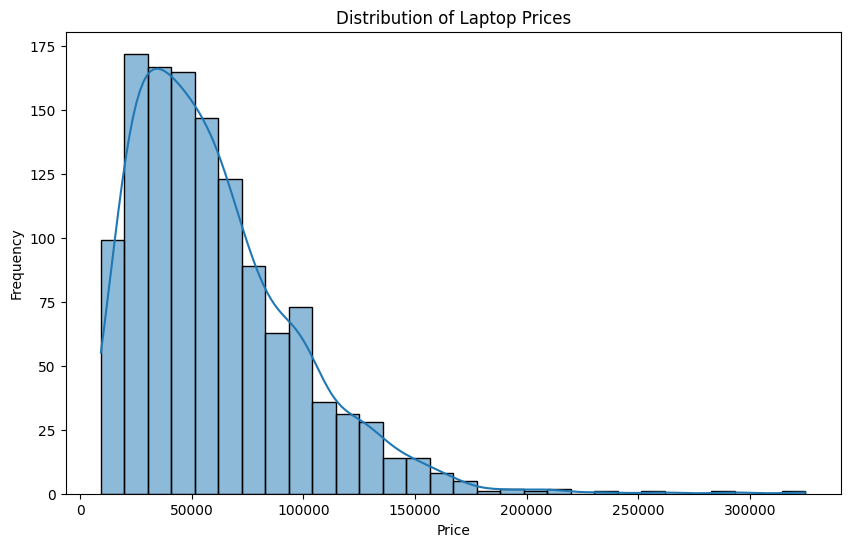

In [22]:
# visulaizing the price distribution
plt.figure(figsize=(10, 6))
sns.histplot(laptops['price'], bins=30, kde=True)
plt.title('Distribution of Laptop Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [23]:
# summary for the price of the laptop
print(laptops['price'].describe())

count      1244.000000
mean      60606.224427
std       37424.636161
min        9270.720000
25%       32655.445200
50%       52693.920000
75%       79813.440000
max      324954.720000
Name: price, dtype: float64


#### Data Preprocessing

In [24]:
# converting prices into 4 categories (low, medium, high, very high)
# using qcut to split the prices into 4 quartiles
laptops['price_category'] = pd.qcut(laptops['price'], q=4, labels=['Low', 'Medium', 'High', 'Very High'])
print(laptops['price_category'].value_counts())

price_category
Medium       312
Low          311
High         311
Very High    310
Name: count, dtype: int64


In [25]:
laptops.head(3)

,company,typename,inches,ram,weight,price,screen_type,screen_width,screen_height,touchscreen,cpu_name,cpu_brand,cpu_speed,hdd,ssd,hybrid,flash_storage,gpu_brand,operating_system,price_category
0,apple,ultrabook,13.3,8,1.37,71378.6832,ips panel retina display,2560,1600,0,intel core i5,intel core i5,2.3,0,128,0,0,intel iris,mac,High
1,apple,ultrabook,13.3,8,1.34,47895.5232,standard,1440,900,0,intel core i5,intel core i5,1.8,0,0,0,128,intel hd,mac,Medium
2,hp,notebook,15.6,8,1.86,30636.0000,full hd,1920,1080,0,intel core i5,intel core i5,2.5,0,256,0,0,intel hd,others/no os,Low


In [ ]:
categorical_columns = laptops.select_dtypes(include=['object']).columns
print("categorical columns selected:", list(categorical_columns))



categorical columns selected: ['company', 'typename', 'screen_type', 'cpu_name', 'cpu_brand', 'gpu_brand', 'operating_system']


In [30]:
# applying one hot encoding
laptops_encoded = pd.get_dummies(laptops, columns=categorical_columns, drop_first=True) 
laptops_encoded.head(3)

,inches,ram,weight,price,screen_width,screen_height,touchscreen,cpu_speed,hdd,ssd,...,gpu_brand_intel graphics,gpu_brand_intel hd,gpu_brand_intel iris,gpu_brand_intel uhd,gpu_brand_nvidia geforce,gpu_brand_nvidia gtx,gpu_brand_nvidia quadro,operating_system_mac,operating_system_others/no os,operating_system_windows
0,13.3,8,1.37,71378.6832,2560,1600,0,2.3,0,128,...,False,False,True,False,False,False,False,True,False,False
1,13.3,8,1.34,47895.5232,1440,900,0,1.8,0,0,...,False,True,False,False,False,False,False,True,False,False
2,15.6,8,1.86,30636.0000,1920,1080,0,2.5,0,256,...,False,True,False,False,False,False,False,False,True,False


#### Model training

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [32]:
# defining my x which is the input and y which is the target
x = laptops_encoded.drop(['price', 'price_category'], axis=1)
y = laptops_encoded['price_category']

In [33]:
# splitting the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)   

In [34]:
# training the model
model = DecisionTreeClassifier()
model.fit(x_train, y_train)
print("Model training completed.")

Model training completed.
